# STAT 404 Project — Search Algorithms and Maze Structure on Pathfinding Efficiency
**Group:** Naufal Prasojo, Chriscenci Susanto, Firila Najma Wahidah, Reyhan Pamungkas · Lab L1B

Analysis follows the proposal: a **split-plot design** with blocking.

| Stratum | Unit | Factors | Error term |
|---|---|---|---|
| Whole plot | maze (270) | Generation method *G* (block, 3), Size *S* (3), Loop density *D* (3) | maze-to-maze error (δ) |
| Subplot | one algorithm run on a maze (1350) | Algorithm *A* (5), *A×S*, *A×D* | run-level error (ε) |

Model (proposal, with the whole-plot error made explicit):

$$Y_{ijklm} = \mu + G_l + S_i + D_j + (SD)_{ij} + \delta_{m(ijl)} + A_k + (AS)_{ik} + (AD)_{jk} + \varepsilon_{ijklm}$$

with $\delta \sim N(0,\sigma^2_\delta)$ (maze effect) and $\varepsilon \sim N(0,\sigma^2)$. Three-way and higher interactions are pooled into ε.
Whole-plot effects are tested against MS(maze), subplot effects against MS(ε).

Responses: `time_s` and `nodes_explored`, analysed on the log scale (both span ~3 orders of magnitude).

In [50]:
suppressPackageStartupMessages({
  library(MASS)      # boxcox (load before dplyr so select() isn't masked)
  library(dplyr); library(tidyr); library(ggplot2)
  library(lme4); library(car); library(patchwork)
})
options(repr.plot.width = 15, repr.plot.height = 4.5, width = 180, digits = 5)
theme_set(theme_bw(base_size = 12))

ALG_LEVELS <- c("bfs", "dijkstra", "astar", "greedy", "random_walk")
df <- read.csv("results_f.csv") %>%
  mutate(A    = factor(algorithm, levels = ALG_LEVELS),
         G    = factor(gen_method),
         S    = factor(size, levels = c(20, 50, 100)),
         D    = factor(loop_density, levels = c(0.05, 0.15, 0.30)),
         maze = factor(maze_id),
         log_time  = log(time_s),
         log_nodes = log(nodes_explored))
cat(dim(df), "| mazes:", nlevels(df$maze), "\n")
head(df)

675 25 | mazes: 135 


,maze_id,seed,gen_method,size,loop_density,rep,loops_added,opt_path_length,alg_order,run_position,⋯,success,path_length,gen_time_s,A,G,S,D,maze,log_time,log_nodes
,<int>,<dbl>,<chr>,<int>,<dbl>,<int>,<int>,<int>,<chr>,<int>,⋯,<int>,<int>,<dbl>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>
1,1,13962645,kruskal,20,0.05,5,18,50,astar-dijkstra-bfs-random_walk-greedy,1,⋯,1,50,0.0019017,astar,kruskal,20,0.05,1,-8.6663,5.4596
2,1,13962645,kruskal,20,0.05,5,18,50,astar-dijkstra-bfs-random_walk-greedy,2,⋯,1,50,0.0019017,dijkstra,kruskal,20,0.05,1,-8.4101,5.9814
3,1,13962645,kruskal,20,0.05,5,18,50,astar-dijkstra-bfs-random_walk-greedy,3,⋯,1,50,0.0019017,bfs,kruskal,20,0.05,1,-8.8292,5.9789
4,1,13962645,kruskal,20,0.05,5,18,50,astar-dijkstra-bfs-random_walk-greedy,4,⋯,1,11648,0.0019017,random_walk,kruskal,20,0.05,1,-5.8022,5.8693
5,1,13962645,kruskal,20,0.05,5,18,50,astar-dijkstra-bfs-random_walk-greedy,5,⋯,1,54,0.0019017,greedy,kruskal,20,0.05,1,-8.6524,5.3230
6,2,1743070153,kruskal,100,0.30,3,2940,198,random_walk-bfs-dijkstra-astar-greedy,1,⋯,1,250962,0.0648081,random_walk,kruskal,100,0.3,2,-2.1753,9.1592


## 1. Design check

In [51]:
cat("Mazes per G x S x D cell:\n")
ftable(xtabs(~ G + S + D, data = distinct(df, maze_id, G, S, D)))
cat("Each algorithm appears exactly once per maze:", all(table(df$maze, df$A) == 1), "\n")
cat("\nRun-position balance (randomization check):\n")
table(df$A, df$run_position)

Mazes per G x S x D cell:


            D 0.05 0.15 0.3
G       S                  
dfs     20       5    5   5
        50       5    5   5
        100      5    5   5
kruskal 20       5    5   5
        50       5    5   5
        100      5    5   5
prim    20       5    5   5
        50       5    5   5
        100      5    5   5

Each algorithm appears exactly once per maze: TRUE 

Run-position balance (randomization check):


             
               1  2  3  4  5
  bfs         26 27 27 28 27
  dijkstra    23 29 23 31 29
  astar       33 24 33 24 21
  greedy      16 25 31 29 34
  random_walk 37 30 21 23 24

### Success rate
Random walk failed on 4 runs (all 100×100, 5% loops) by hitting the 2,000,000-step cap, so their time / nodes are **right-censored**.
They're kept in the main analysis (dropping them would make the design unbalanced and bias RW downward); Section 8 reruns without them as a sensitivity check.

In [52]:
df %>% group_by(A) %>% summarise(success_rate = mean(success), failures = sum(success == 0), n = n())
df %>% filter(success == 0) %>% select(maze_id, G, S, D, algorithm, time_s, nodes_explored, steps)

A,success_rate,failures,n
<fct>,<dbl>,<int>,<int>
bfs,1.00000,0,135
dijkstra,1.00000,0,135
astar,1.00000,0,135
greedy,1.00000,0,135
random_walk,0.98519,2,135


maze_id,G,S,D,algorithm,time_s,nodes_explored,steps
<int>,<fct>,<fct>,<fct>,<chr>,<dbl>,<int>,<int>
4,prim,100,0.05,random_walk,0.63058,9936,2000000
99,kruskal,50,0.05,random_walk,0.29670,2476,500000


## 2. Descriptive summaries

In [53]:
df %>% group_by(A) %>%
  summarise(time_med = median(time_s), time_mean = mean(time_s),
            nodes_med = median(nodes_explored), nodes_mean = mean(nodes_explored),
            path_len_med = median(path_length), opt_path_med = median(opt_path_length))

A,time_med,time_mean,nodes_med,nodes_mean,path_len_med,opt_path_med
<fct>,<dbl>,<dbl>,<int>,<dbl>,<int>,<int>
bfs,0.0007977,0.00191325,2497,4269.70,104,104
dijkstra,0.0020143,0.00467557,2498,4271.70,104,104
astar,0.0014475,0.00311950,1065,1935.39,104,104
greedy,0.0002494,0.00035471,187,247.47,124,104
random_walk,0.0188011,0.06640375,1784,3362.61,39002,104


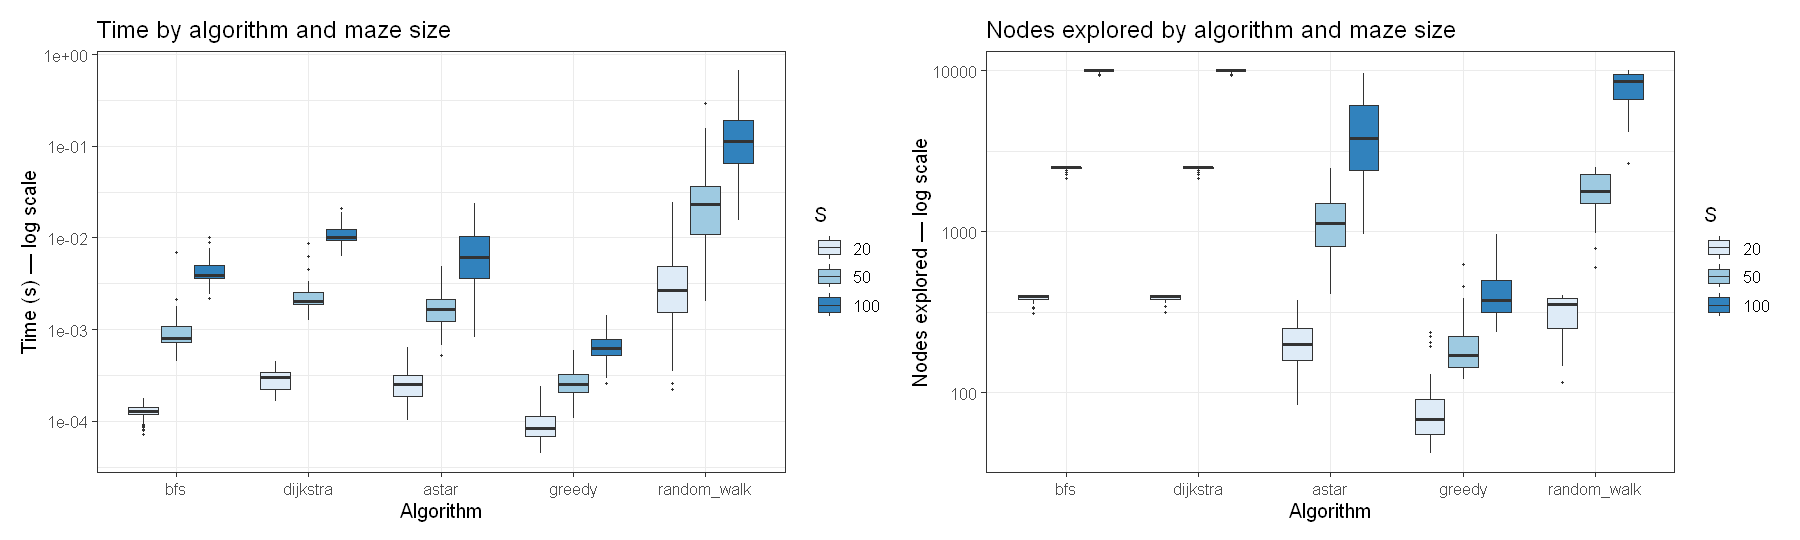

In [54]:
p1 <- ggplot(df, aes(A, time_s, fill = S)) + geom_boxplot(outlier.size = .6) +
  scale_y_log10() + scale_fill_brewer(palette = "Blues") +
  labs(x = "Algorithm", y = "Time (s) — log scale", title = "Time by algorithm and maze size")
p2 <- ggplot(df, aes(A, nodes_explored, fill = S)) + geom_boxplot(outlier.size = .6) +
  scale_y_log10() + scale_fill_brewer(palette = "Blues") +
  labs(x = "Algorithm", y = "Nodes explored — log scale", title = "Nodes explored by algorithm and maze size")
p1 + p2

Note: on an unweighted grid Dijkstra and BFS expand essentially the same nodes (same frontier order up to ties), so their node counts are nearly identical; they differ mainly in time (priority-queue overhead).

## 3. Split-plot ANOVA
Fitted with `aov(... + Error(maze))`, which splits the analysis into the two strata automatically:
- **`Error: maze`** = whole-plot stratum (G, S, D, S×D vs maze-to-maze error)
- **`Error: Within`** = subplot stratum (A, A×S, A×D vs run-level error)

In [55]:
split_plot <- function(data, y, sub = "A + A:S + A:D") {
  f   <- as.formula(paste(y, "~ G + S*D +", sub, "+ Error(maze)"))
  fit <- aov(f, data = data)
  s   <- summary(fit)
  wp  <- s[["Error: maze"]][[1]];  sp <- s[["Error: Within"]][[1]]
  mk  <- function(t, stratum) data.frame(Stratum = stratum, Term = trimws(rownames(t)),
                                         t, check.names = FALSE, row.names = NULL)
  tab <- rbind(mk(wp, "Whole plot"), mk(sp, "Subplot"))
  tab$Term[tab$Term == "Residuals"] <- c("Whole-plot error [maze(G,S,D)]", "Subplot error")
  tab$Term[tab$Term == "G"] <- "G (block)"
  tab$pct_SS <- 100 * tab$`Sum Sq` / sum(tab$`Sum Sq`)
  r_wp <- nrow(wp); r_sp <- nrow(sp)
  list(fit = fit, tab = tab,
       ms_wp = wp[r_wp, "Mean Sq"], df_wp = wp[r_wp, "Df"],
       ms_sp = sp[r_sp, "Mean Sq"], df_sp = sp[r_sp, "Df"])
}

res <- list()
for (y in c("log_time", "log_nodes")) {
  res[[y]] <- split_plot(df, y)
  cat("\n=====", y, "=====\n"); print(res[[y]]$tab, digits = 4)
}


===== log_time =====
     Stratum                           Term  Df   Sum Sq  Mean Sq  F value     Pr(>F)   pct_SS
1 Whole plot                      G (block)   2    4.580   2.2900    5.503  5.130e-03  0.16591
2 Whole plot                              S   2 1158.273 579.1364 1391.793  1.130e-85 41.95664
3 Whole plot                              D   2   11.010   5.5049   13.229  6.198e-06  0.39881
4 Whole plot                            S:D   4    1.921   0.4802    1.154  3.345e-01  0.06957
5 Whole plot Whole-plot error [maze(G,S,D)] 124   51.597   0.4161       NA         NA  1.86904
6    Subplot                              A   4 1331.205 332.8012 1338.666 3.998e-272 48.22083
7    Subplot                            S:A   8   51.028   6.3785   25.657  1.896e-33  1.84842
8    Subplot                            D:A   8   21.754   2.7192   10.938  2.634e-14  0.78799
9    Subplot                  Subplot error 520  129.275   0.2486       NA         NA  4.68280

===== log_nodes =====
     

In [56]:
# sanity check: SS from both strata add up to the corrected total SS
for (y in names(res)) cat(y, sum(res[[y]]$tab$`Sum Sq`), sum((df[[y]] - mean(df[[y]]))^2), "\n")

log_time 2760.6 2760.6 
log_nodes 1609.5 1609.5 


### Mixed-model cross-check (REML)
Same model fitted with `lmer` and a random maze intercept. Gives the variance components directly.

In [57]:
vc <- lapply(names(res), function(y) {
  m  <- lmer(as.formula(paste(y, "~ G + S*D + A + A:S + A:D + (1 | maze)")), data = df, REML = TRUE)
  res[[y]]$lmer <<- m
  v  <- as.data.frame(VarCorr(m))$vcov
  data.frame(response = y, sigma2_maze = v[1], sigma2_error = v[2], ICC = v[1] / sum(v))
})
do.call(rbind, vc)

response,sigma2_maze,sigma2_error,ICC
<chr>,<dbl>,<dbl>,<dbl>
log_time,0.0335003,0.248607,0.118750
log_nodes,0.0050634,0.077291,0.061483


### Share of variation: maze vs algorithm (Objective 3)
From the ANOVA sums of squares: everything in the whole-plot stratum is "maze" (structure + maze-to-maze noise); the algorithm main effect and its interactions are "algorithm".

response,Maze_total,Maze_structure_SDG,Maze_error,Algorithm_main,Algorithm_x_structure,Subplot_error
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
log_time,44.460,42.591,1.86904,48.221,2.6364,4.6828
log_nodes,58.881,58.091,0.79053,35.520,3.1020,2.4972


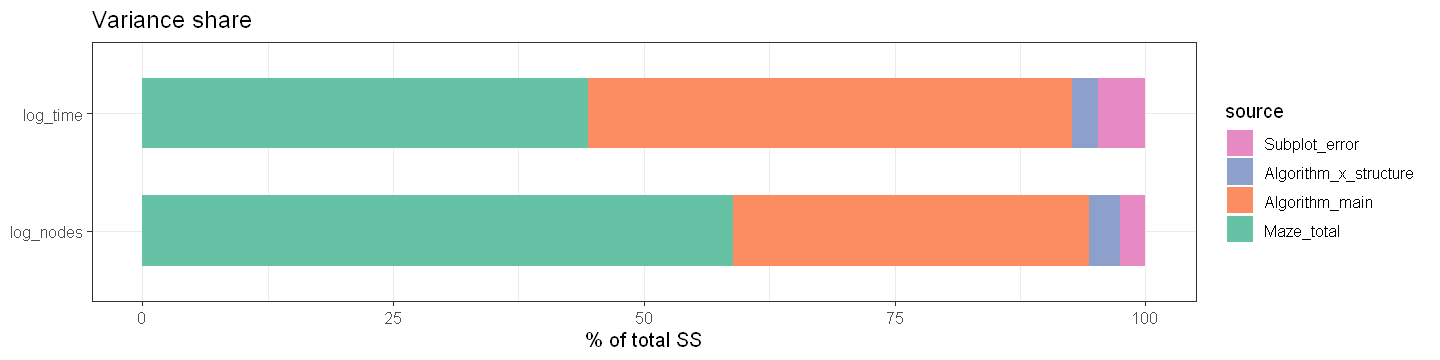

In [58]:
share <- do.call(rbind, lapply(names(res), function(y) {
  t <- res[[y]]$tab; tot <- sum(t$`Sum Sq`); ss <- setNames(t$`Sum Sq`, t$Term)
  data.frame(response = y,
             Maze_total            = 100 * sum(t$`Sum Sq`[t$Stratum == "Whole plot"]) / tot,
             Maze_structure_SDG    = 100 * sum(ss[c("G (block)", "S", "D", "S:D")]) / tot,
             Maze_error            = 100 * ss["Whole-plot error [maze(G,S,D)]"] / tot,
             Algorithm_main        = 100 * ss["A"] / tot,
             Algorithm_x_structure = 100 * sum(ss[c("S:A", "D:A")]) / tot,
             Subplot_error         = 100 * ss["Subplot error"] / tot, row.names = NULL)
}))
share

options(repr.plot.width = 12, repr.plot.height = 3)
share %>% select(response, Maze_total, Algorithm_main, Algorithm_x_structure, Subplot_error) %>%
  pivot_longer(-response, names_to = "source", values_to = "pct") %>%
  mutate(source = factor(source, levels = rev(c("Maze_total", "Algorithm_main", "Algorithm_x_structure", "Subplot_error")))) %>%
  ggplot(aes(pct, response, fill = source)) + geom_col(width = .6) +
  scale_fill_brewer(palette = "Set2", direction = -1) + labs(x = "% of total SS", y = NULL, title = "Variance share")
options(repr.plot.width = 15, repr.plot.height = 4.5)

## 4. Whole-plot analysis (maze level)
Each point is a maze mean over the 5 algorithms. These plots show the effects tested against the whole-plot error.

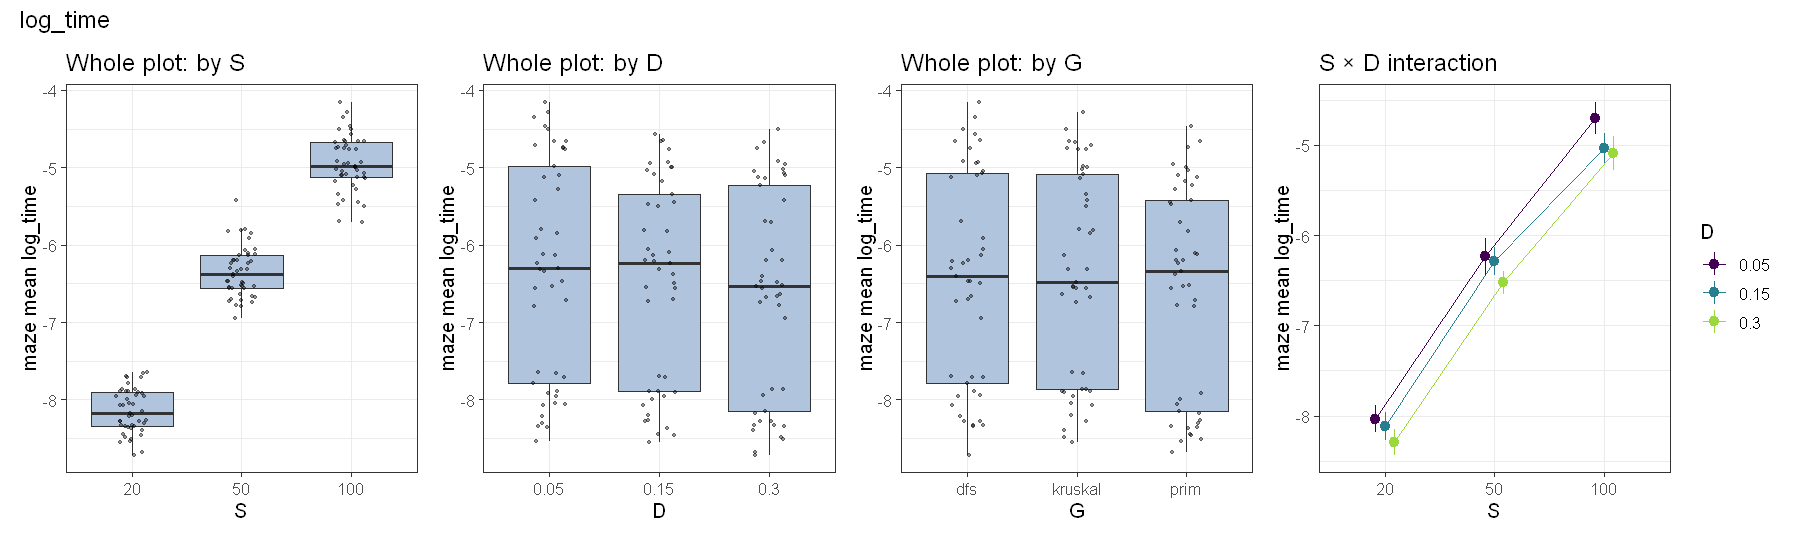

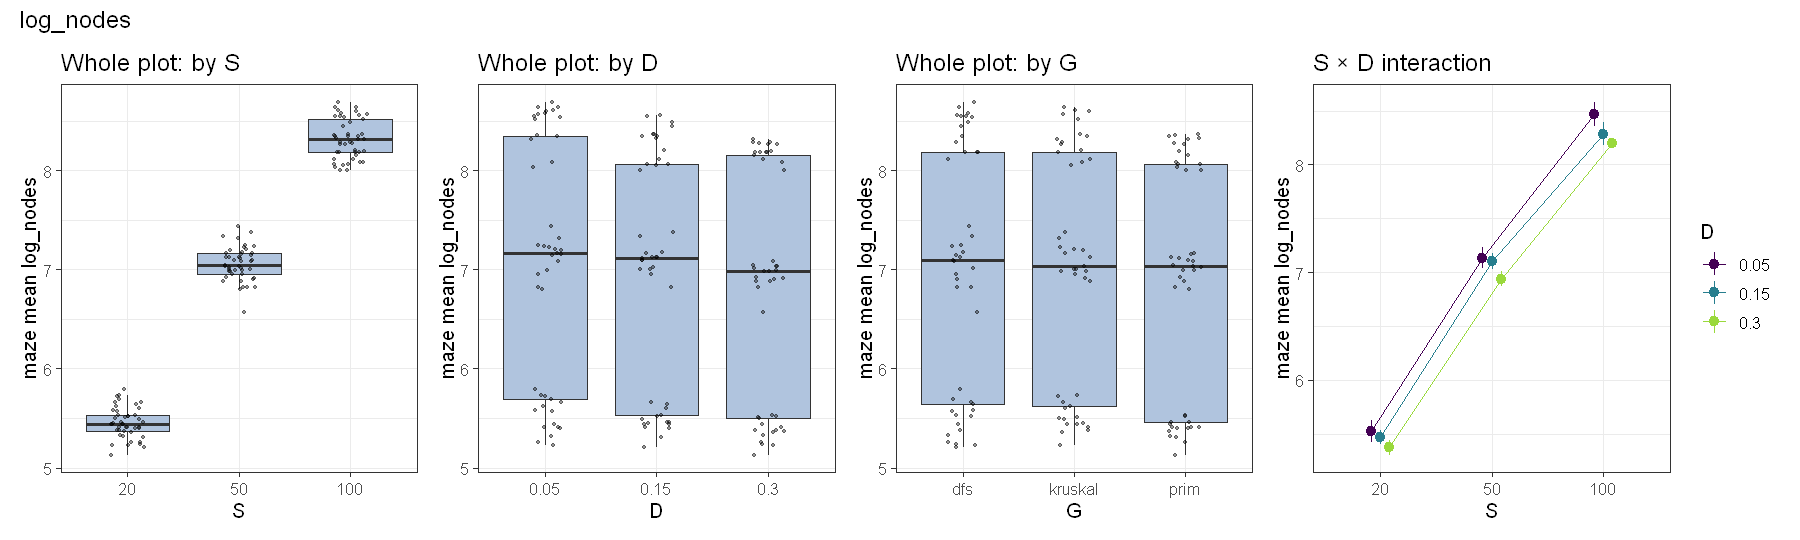

In [59]:
wp <- df %>% group_by(maze_id, G, S, D) %>%
  summarise(log_time = mean(log_time), log_nodes = mean(log_nodes), .groups = "drop")
ci95 <- function(x) { m <- mean(x); h <- qt(.975, length(x) - 1) * sd(x) / sqrt(length(x))
                      data.frame(y = m, ymin = m - h, ymax = m + h) }

for (y in c("log_time", "log_nodes")) {
  box_by <- function(f) ggplot(wp, aes(.data[[f]], .data[[y]])) +
    geom_boxplot(fill = "lightsteelblue", outlier.shape = NA) +
    geom_jitter(width = .15, size = .8, alpha = .4) +
    labs(x = f, y = paste("maze mean", y), title = paste("Whole plot: by", f))
  sd_plot <- ggplot(wp, aes(S, .data[[y]], colour = D, group = D)) +
    stat_summary(fun = mean, geom = "line", position = position_dodge(.25)) +
    stat_summary(fun.data = ci95, geom = "pointrange", position = position_dodge(.25)) +
    scale_colour_viridis_d(end = .85) + labs(y = paste("maze mean", y), title = "S × D interaction")
  print(box_by("S") + box_by("D") + box_by("G") + sd_plot + plot_layout(nrow = 1) +
        plot_annotation(title = y))
}

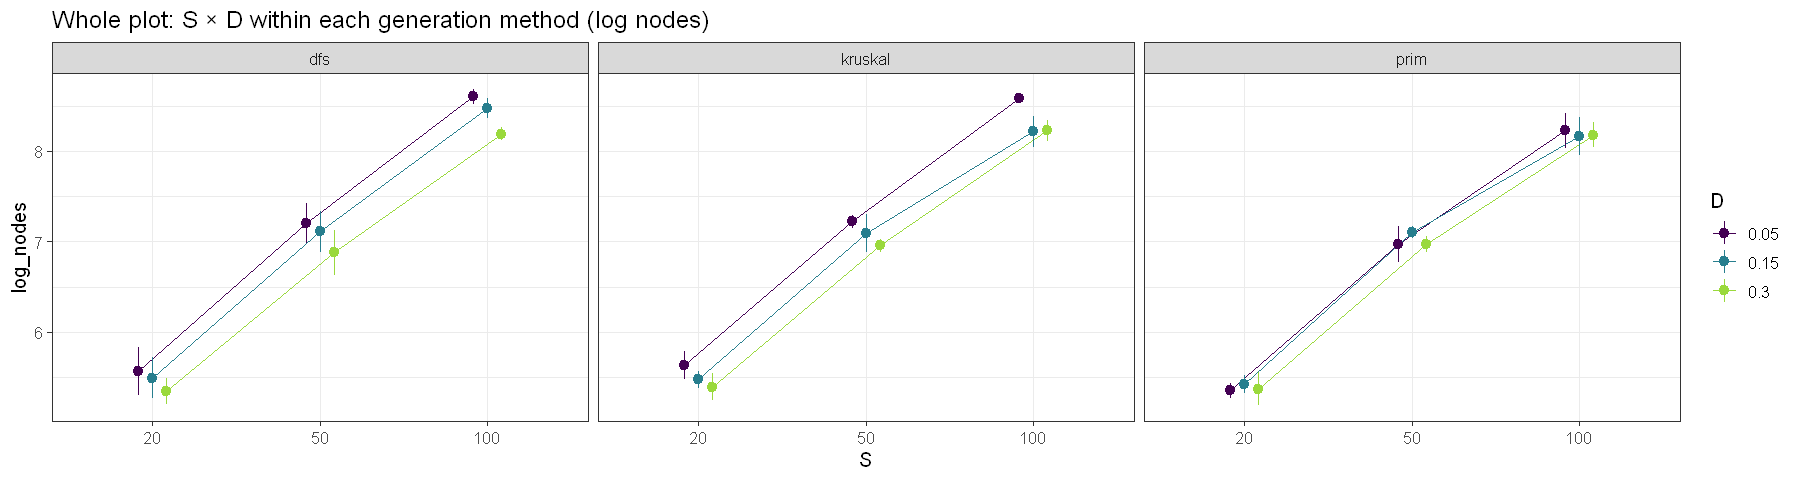

In [60]:
# S x D within each block (G)
options(repr.plot.height = 4)
ggplot(wp, aes(S, log_nodes, colour = D, group = D)) +
  stat_summary(fun = mean, geom = "line", position = position_dodge(.25)) +
  stat_summary(fun.data = ci95, geom = "pointrange", position = position_dodge(.25)) +
  facet_wrap(~ G) + scale_colour_viridis_d(end = .85) +
  labs(title = "Whole plot: S × D within each generation method (log nodes)")
options(repr.plot.height = 4.5)

### Whole-plot trend contrasts (linear / quadratic in S and D)
Orthogonal polynomials from `contr.poly()` using the actual (unequally spaced) level values; tested with the whole-plot error.

In [61]:
wp_trends <- function(y) {
  m <- lm(as.formula(paste(y, "~ G + S*D")), data = wp)
  mse <- sigma(m)^2; dfe <- df.residual(m); tc <- qt(.975, dfe)
  out <- list()
  for (f in c("S", "D")) {
    lv    <- as.numeric(levels(wp[[f]]))
    means <- tapply(wp[[y]], wp[[f]], mean); n <- sum(wp[[f]] == levels(wp[[f]])[1])
    P     <- contr.poly(3, scores = lv)
    for (j in 1:2) {
      c <- P[, j]; est <- sum(c * means); se <- sqrt(mse * sum(c^2) / n); t <- est / se
      out[[length(out) + 1]] <- data.frame(factor = f, trend = c("linear", "quadratic")[j],
        coef = paste(round(c, 3), collapse = ", "), estimate = est, SE = se, t = t,
        p = 2 * pt(-abs(t), dfe), lo95 = est - tc * se, hi95 = est + tc * se)
    }
  }
  do.call(rbind, out)
}
for (y in names(res)) { cat("\n", y, "\n"); print(wp_trends(y), digits = 4) }


 log_time 
  factor     trend                  coef estimate    SE        t         p     lo95    hi95
1      S    linear -0.642, -0.117, 0.758  2.21712 0.043  51.5557 1.277e-85  2.13200  2.3022
2      S quadratic  0.505, -0.808, 0.303 -0.48195 0.043 -11.2069 1.458e-20 -0.56706 -0.3968
3      D    linear -0.656, -0.094, 0.749 -0.21981 0.043  -5.1114 1.177e-06 -0.30493 -0.1347
4      D quadratic  0.487, -0.811, 0.324  0.02479 0.043   0.5763 5.654e-01 -0.06033  0.1099

 log_nodes 
  factor     trend                  coef  estimate      SE        t          p    lo95     hi95
1      S    linear -0.642, -0.117, 0.758  1.984638 0.02136  92.9355 1.626e-116  1.9424  2.02691
2      S quadratic  0.505, -0.808, 0.303 -0.427782 0.02136 -20.0319  1.096e-40 -0.4700 -0.38551
3      D    linear -0.656, -0.094, 0.749 -0.146068 0.02136  -6.8400  3.214e-10 -0.1883 -0.10380
4      D quadratic  0.487, -0.811, 0.324  0.005968 0.02136   0.2795  7.803e-01 -0.0363  0.04824


### Estimated whole-plot means (95% CI, whole-plot error)
`geo_*` columns are back-transformed (geometric means).

In [62]:
wp_means <- function(y) {
  m <- lm(as.formula(paste(y, "~ G + S*D")), data = wp); tc <- qt(.975, df.residual(m))
  do.call(rbind, lapply(c("S", "D", "G"), function(f) {
    wp %>% group_by(level = .data[[f]]) %>%
      summarise(mean_log = mean(.data[[y]]), n = n(), .groups = "drop") %>%
      mutate(factor = f, se = sigma(m) / sqrt(n), lo = mean_log - tc * se, hi = mean_log + tc * se,
             geo_mean = exp(mean_log), geo_lo = exp(lo), geo_hi = exp(hi), level = as.character(level)) %>%
      select(factor, level, mean_log, lo, hi, geo_mean, geo_lo, geo_hi)
  }))
}
for (y in names(res)) { cat("\n", y, "\n"); print(as.data.frame(wp_means(y)), digits = 4) }


 log_time 
  factor   level mean_log     lo     hi  geo_mean    geo_lo    geo_hi
1      S      20   -8.145 -8.230 -8.060 0.0002903 0.0002666 0.0003161
2      S      50   -6.348 -6.433 -6.263 0.0017502 0.0016074 0.0019057
3      S     100   -4.944 -5.029 -4.859 0.0071261 0.0065446 0.0077592
4      D    0.05   -6.323 -6.408 -6.238 0.0017950 0.0016486 0.0019545
5      D    0.15   -6.478 -6.564 -6.393 0.0015362 0.0014109 0.0016727
6      D     0.3   -6.636 -6.721 -6.550 0.0013128 0.0012057 0.0014295
7      G     dfs   -6.436 -6.521 -6.351 0.0016028 0.0014720 0.0017452
8      G kruskal   -6.407 -6.492 -6.321 0.0016507 0.0015160 0.0017973
9      G    prim   -6.594 -6.679 -6.509 0.0013683 0.0012567 0.0014899

 log_nodes 
  factor   level mean_log    lo    hi geo_mean geo_lo geo_hi
1      S      20    5.454 5.411 5.496    233.6  224.0  243.7
2      S      50    7.057 7.015 7.099   1161.2 1113.1 1211.3
3      S     100    8.318 8.276 8.360   4097.2 3927.7 4274.1
4      D    0.05    7.042 6.999

## 5. Subplot analysis (algorithm within maze)
Algorithm and its interactions with maze structure, tested against the subplot error.

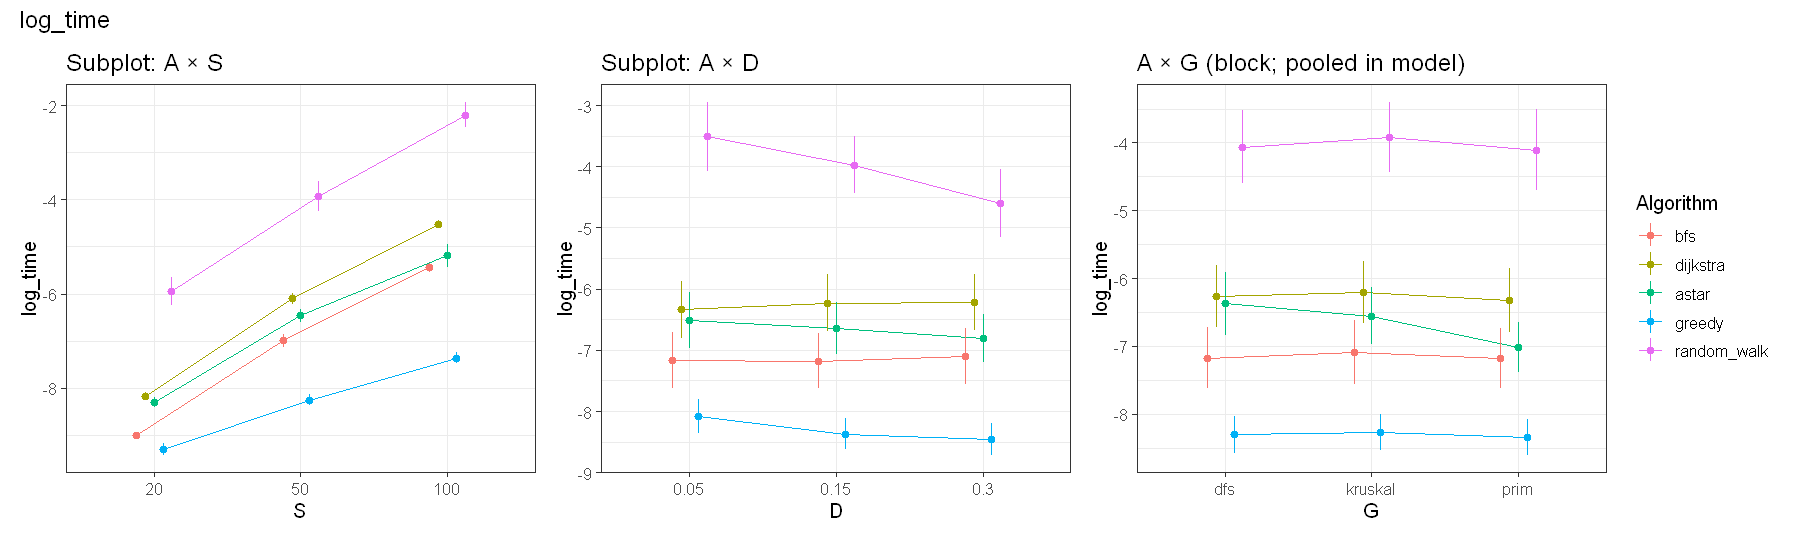

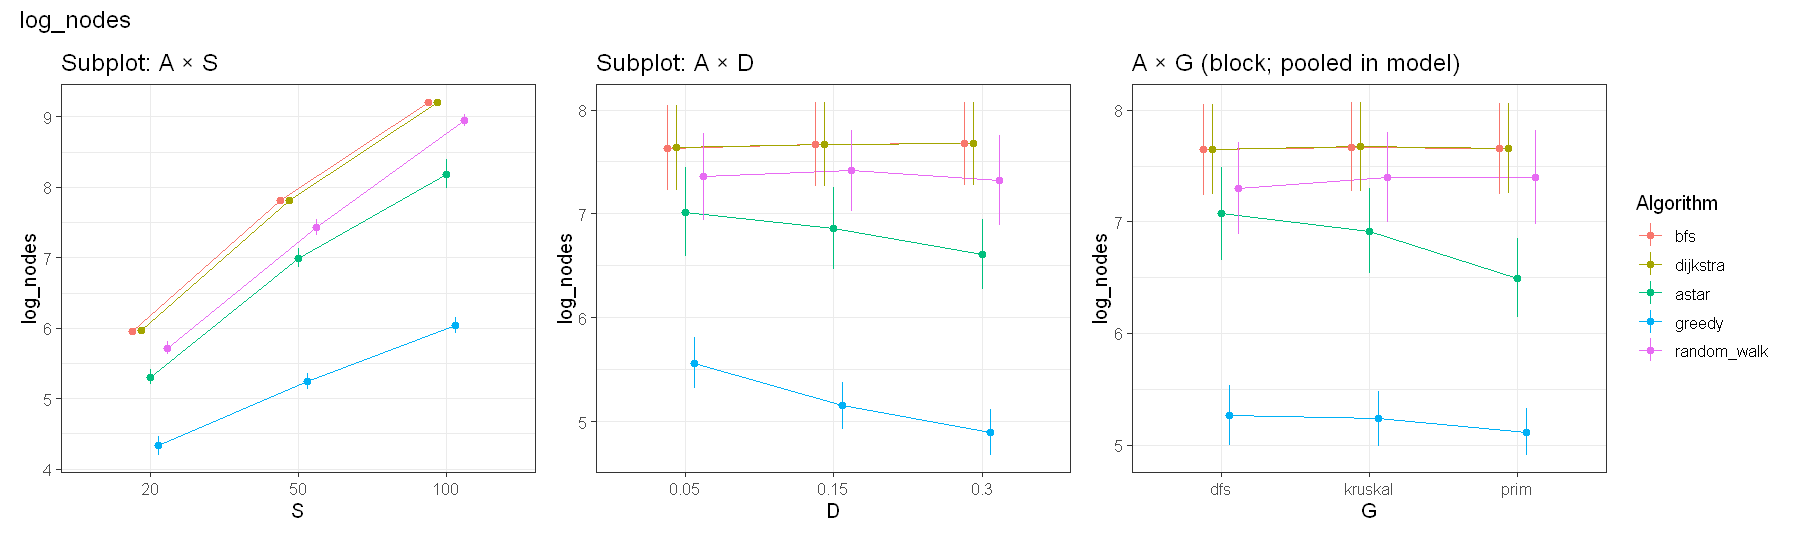

In [63]:
int_plot <- function(y, f, ttl) ggplot(df, aes(.data[[f]], .data[[y]], colour = A, group = A)) +
  stat_summary(fun = mean, geom = "line", position = position_dodge(.3)) +
  stat_summary(fun.data = ci95, geom = "pointrange", size = .3, position = position_dodge(.3)) +
  labs(title = ttl, colour = "Algorithm")
for (y in c("log_time", "log_nodes"))
  print(int_plot(y, "S", "Subplot: A × S") + int_plot(y, "D", "Subplot: A × D") +
        int_plot(y, "G", "A × G (block; pooled in model)") +
        plot_layout(guides = "collect") + plot_annotation(title = y))

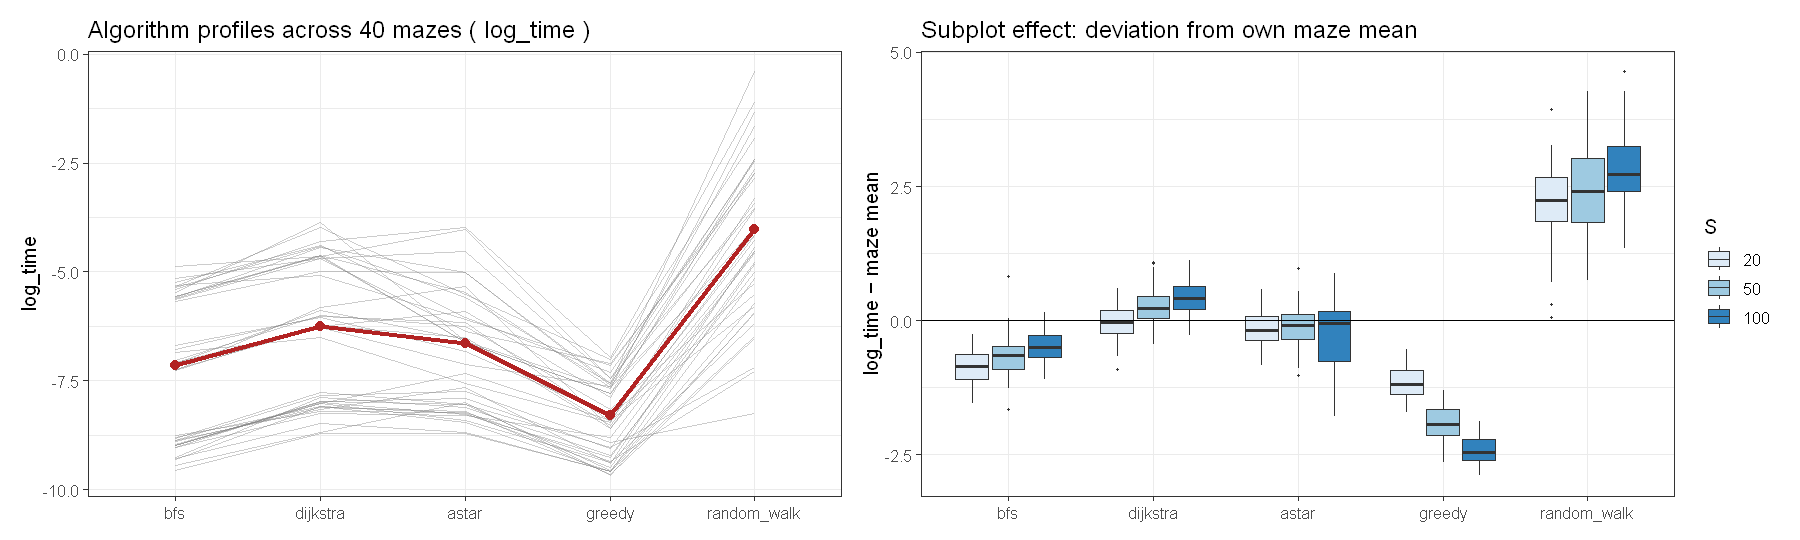

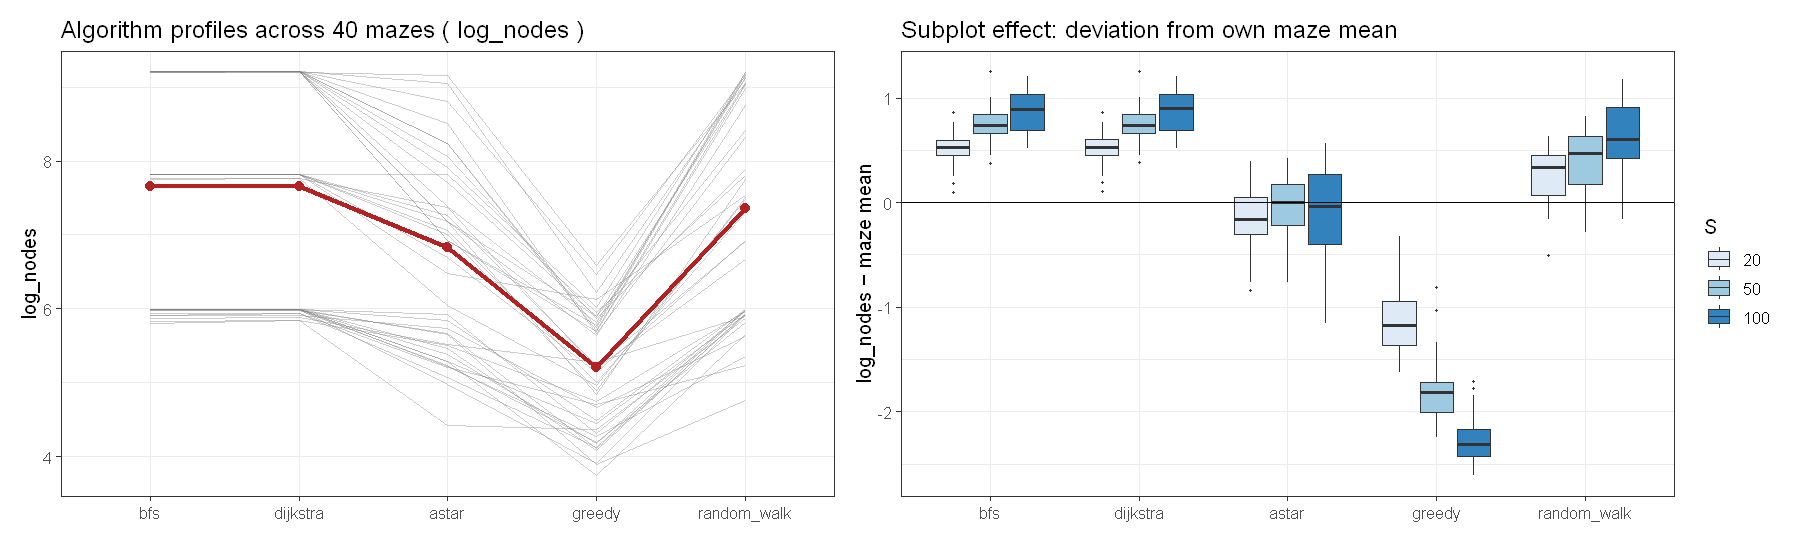

In [64]:
# Within-maze algorithm effects: subtract each maze's mean -> removes all whole-plot variation
set.seed(1); sample_mazes <- sample(unique(df$maze_id), 40)
for (y in c("log_time", "log_nodes")) {
  d <- df %>% group_by(maze_id) %>% mutate(within = .data[[y]] - mean(.data[[y]])) %>% ungroup()
  overall <- df %>% group_by(A) %>% summarise(m = mean(.data[[y]]))
  pa <- ggplot(filter(d, maze_id %in% sample_mazes), aes(A, .data[[y]], group = maze_id)) +
    geom_line(colour = "grey50", alpha = .4) +
    geom_line(data = overall, aes(A, m, group = 1), colour = "firebrick", linewidth = 1.3, inherit.aes = FALSE) +
    geom_point(data = overall, aes(A, m), colour = "firebrick", size = 2.5, inherit.aes = FALSE) +
    labs(title = paste("Algorithm profiles across 40 mazes (", y, ")"), x = NULL)
  pb <- ggplot(d, aes(A, within, fill = S)) + geom_boxplot(outlier.size = .5) +
    geom_hline(yintercept = 0) + scale_fill_brewer(palette = "Blues") +
    labs(y = paste(y, "− maze mean"), title = "Subplot effect: deviation from own maze mean", x = NULL)
  print(pa + pb)
}

In [65]:
# Share of mazes where each algorithm is best (rank 1), by S and D. Does the winner change?
for (y in c("log_time", "log_nodes")) {
  cat("\n", y, "\n")
  df %>% group_by(maze_id) %>% mutate(best = rank(.data[[y]]) == 1) %>%
    group_by(S, D, A) %>% summarise(p_best = mean(best), .groups = "drop") %>%
    pivot_wider(names_from = A, values_from = p_best) %>% as.data.frame() %>% print(digits = 2)
}


 log_time 
    S    D  bfs dijkstra astar greedy random_walk
1  20 0.05 0.53        0     0   0.47           0
2  20 0.15 0.13        0     0   0.87           0
3  20  0.3 0.00        0     0   1.00           0
4  50 0.05 0.00        0     0   1.00           0
5  50 0.15 0.00        0     0   1.00           0
6  50  0.3 0.00        0     0   1.00           0
7 100 0.05 0.00        0     0   1.00           0
8 100 0.15 0.00        0     0   1.00           0
9 100  0.3 0.00        0     0   1.00           0

 log_nodes 
    S    D bfs dijkstra astar greedy random_walk
1  20 0.05   0        0     0      1           0
2  20 0.15   0        0     0      1           0
3  20  0.3   0        0     0      1           0
4  50 0.05   0        0     0      1           0
5  50 0.15   0        0     0      1           0
6  50  0.3   0        0     0      1           0
7 100 0.05   0        0     0      1           0
8 100 0.15   0        0     0      1           0
9 100  0.3   0        0     0     

### Planned subplot contrasts (proposal)
Estimated on the log scale with the subplot error MS; `ratio` = exp(estimate), i.e. the multiplicative difference in geometric means.
- A* vs Dijkstra
- Informed (A*, Greedy) vs Uninformed (BFS, Dijkstra)
- Random walk vs the rest

In [66]:
contrasts_list <- list(
  "A* vs Dijkstra"         = c(bfs = 0,   dijkstra = -1,  astar = 1,   greedy = 0,   random_walk = 0),
  "Informed vs Uninformed" = c(bfs = -.5, dijkstra = -.5, astar = .5,  greedy = .5,  random_walk = 0),
  "Random walk vs rest"    = c(bfs = -.25, dijkstra = -.25, astar = -.25, greedy = -.25, random_walk = 1))

sub_contrasts <- function(y, by = NULL) {
  mse <- res[[y]]$ms_sp; dfe <- res[[y]]$df_sp; tc <- qt(.975, dfe)
  groups <- if (is.null(by)) list(all = df) else split(df, df[[by]])
  do.call(rbind, lapply(names(groups), function(g) {
    d <- groups[[g]]; means <- tapply(d[[y]], d$A, mean)[ALG_LEVELS]; n <- sum(d$A == "bfs")
    do.call(rbind, lapply(names(contrasts_list), function(nm) {
      c <- contrasts_list[[nm]][ALG_LEVELS]; est <- sum(c * means)
      se <- sqrt(mse * sum(c^2) / n); t <- est / se
      data.frame(level = g, contrast = nm, estimate = est, SE = se, t = t, p = 2 * pt(-abs(t), dfe),
                 lo95 = est - tc * se, hi95 = est + tc * se,
                 ratio = exp(est), ratio_lo = exp(est - tc * se), ratio_hi = exp(est + tc * se))
    }))
  }))
}
for (y in names(res)) { cat("\n", y, "\n"); print(sub_contrasts(y)[, -1], digits = 4) }


 log_time 
                contrast estimate      SE       t          p    lo95    hi95   ratio ratio_lo ratio_hi
1         A* vs Dijkstra  -0.3858 0.06069  -6.357  4.504e-10 -0.5050 -0.2666  0.6799   0.6035   0.7660
2 Informed vs Uninformed  -0.7709 0.04291 -17.965  1.709e-56 -0.8552 -0.6866  0.4626   0.4252   0.5033
3    Random walk vs rest   3.0631 0.04798  63.843 3.261e-248  2.9688  3.1573 21.3933  19.4690  23.5078

 log_nodes 
                contrast estimate      SE      t          p    lo95    hi95  ratio ratio_lo ratio_hi
1         A* vs Dijkstra  -0.8305 0.03384 -24.54  6.324e-89 -0.8970 -0.7641 0.4358   0.4078   0.4658
2 Informed vs Uninformed  -1.6413 0.02393 -68.60 1.043e-262 -1.6883 -1.5943 0.1937   0.1848   0.2030
3    Random walk vs rest   0.5277 0.02675  19.72  4.491e-65  0.4751  0.5802 1.6950   1.6082   1.7865


In [67]:
# Same contrasts within each maze size / loop density (ratio scale)
for (y in names(res)) for (by in c("S", "D")) {
  cat("\n", y, "— contrast ratios by", by, "\n")
  sub_contrasts(y, by) %>% select(level, contrast, ratio) %>%
    pivot_wider(names_from = level, values_from = ratio) %>% as.data.frame() %>% print(digits = 3)
}


 log_time — contrast ratios by S 
                contrast     20     50    100
1         A* vs Dijkstra  0.875  0.701  0.513
2 Informed vs Uninformed  0.808  0.446  0.275
3    Random walk vs rest 15.457 20.563 30.805

 log_time — contrast ratios by D 
                contrast   0.05   0.15    0.3
1         A* vs Dijkstra  0.848  0.666  0.557
2 Informed vs Uninformed  0.581  0.449  0.379
3    Random walk vs rest 33.543 22.922 12.734

 log_nodes — contrast ratios by S 
                contrast    20    50   100
1         A* vs Dijkstra 0.519 0.442 0.361
2 Informed vs Uninformed 0.319 0.185 0.123
3    Random walk vs rest 1.387 1.595 2.202

 log_nodes — contrast ratios by D 
                contrast  0.05  0.15   0.3
1         A* vs Dijkstra 0.538 0.447 0.345
2 Informed vs Uninformed 0.261 0.190 0.146
3    Random walk vs rest 1.483 1.785 1.840


### Estimated algorithm means and A × S cell means (95% CI)
Algorithm marginal means use the subplot error. A × S cell means compare across mazes, so their SE combines both strata:
$\mathrm{Var}(\bar y_{ik}) = \frac{MS_{wp} + (a-1)MS_{sp}}{a\,n}$, with Satterthwaite df.

In [68]:
alg_means <- function(y) {
  tc <- qt(.975, res[[y]]$df_sp)
  df %>% group_by(A) %>% summarise(mean_log = mean(.data[[y]]), n = n()) %>%
    mutate(se = sqrt(res[[y]]$ms_sp / n), lo = mean_log - tc * se, hi = mean_log + tc * se,
           geo_mean = exp(mean_log), geo_lo = exp(lo), geo_hi = exp(hi)) %>% select(-n, -se)
}
cell_means <- function(y, f = "S", a = 5) {
  r <- res[[y]]; num <- r$ms_wp + (a - 1) * r$ms_sp
  nu <- num^2 / (r$ms_wp^2 / r$df_wp + ((a - 1) * r$ms_sp)^2 / r$df_sp)
  out <- df %>% group_by(level = .data[[f]], A) %>% summarise(mean_log = mean(.data[[y]]), n = n(), .groups = "drop") %>%
    mutate(se = sqrt(num / (a * n)), lo = mean_log - qt(.975, nu) * se, hi = mean_log + qt(.975, nu) * se,
           geo_mean = exp(mean_log))
  attr(out, "df") <- nu; out
}
for (y in names(res)) {
  cat("\n", y, "— algorithm means\n"); print(as.data.frame(alg_means(y)), digits = 4)
  cm <- cell_means(y)
  cat(y, "— A × S geometric cell means (Satterthwaite df =", round(attr(cm, "df"), 1), ")\n")
  cm %>% select(level, A, geo_mean) %>% pivot_wider(names_from = A, values_from = geo_mean) %>%
    as.data.frame() %>% print(digits = 4)
}


 log_time — algorithm means
            A mean_log     lo     hi  geo_mean    geo_lo    geo_hi
1         bfs   -7.148 -7.233 -7.064 0.0007862 0.0007226 0.0008553
2    dijkstra   -6.264 -6.348 -6.179 0.0019041 0.0017501 0.0020715
3       astar   -6.650 -6.734 -6.565 0.0012946 0.0011899 0.0014085
4      greedy   -8.304 -8.389 -8.220 0.0002474 0.0002274 0.0002692
5 random_walk   -4.028 -4.113 -3.944 0.0178020 0.0163627 0.0193679
log_time — A × S geometric cell means (Satterthwaite df = 603.3 )
  level       bfs dijkstra     astar    greedy random_walk
1    20 0.0001228 0.000284 0.0002486 9.161e-05    0.002595
2    50 0.0009157 0.002240 0.0015694 2.594e-04    0.019658
3   100 0.0043205 0.010850 0.0055614 6.373e-04    0.110597

 log_nodes — algorithm means
            A mean_log    lo    hi geo_mean geo_lo geo_hi
1         bfs    7.657 7.610 7.704   2115.7 2018.5 2217.5
2    dijkstra    7.659 7.612 7.706   2119.9 2022.5 2221.9
3       astar    6.829 6.782 6.876    923.9  881.5  968.4
4    

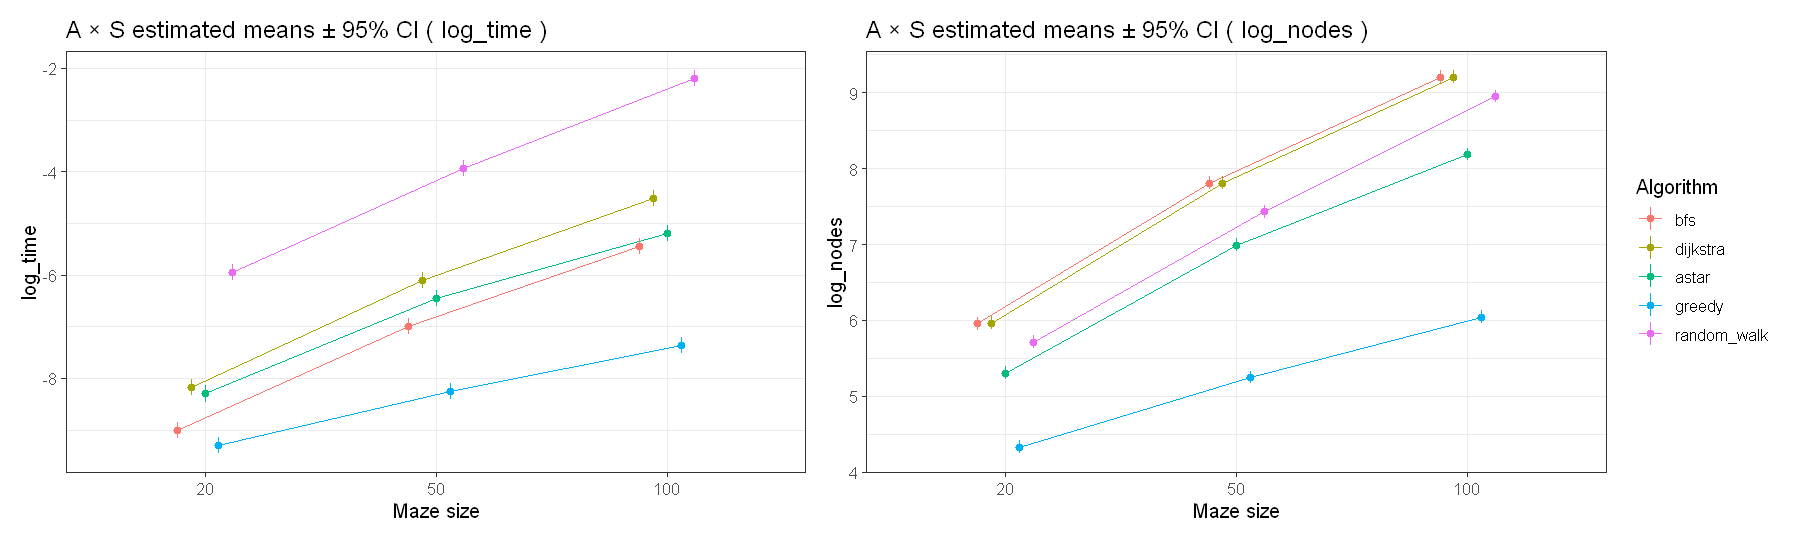

In [69]:
plots <- lapply(c("log_time", "log_nodes"), function(y)
  ggplot(cell_means(y), aes(level, mean_log, colour = A, group = A)) +
    geom_line(position = position_dodge(.3)) +
    geom_pointrange(aes(ymin = lo, ymax = hi), size = .3, position = position_dodge(.3)) +
    labs(x = "Maze size", y = y, title = paste("A × S estimated means ± 95% CI (", y, ")"), colour = "Algorithm"))
plots[[1]] + plots[[2]] + plot_layout(guides = "collect")

## 6. Diagnostics
- Subplot residuals (ε̂, from `lm(y ~ maze + A + A:S + A:D)`): residuals vs fitted by algorithm, normal Q-Q
- Whole-plot residuals (δ̂, maze effects from the maze-mean model): normal Q-Q

log_time : Levene across algorithms p = 6.28e-31 
        bfs    dijkstra       astar      greedy random_walk 
     0.3108      0.2822      0.4560      0.2972      0.7016 


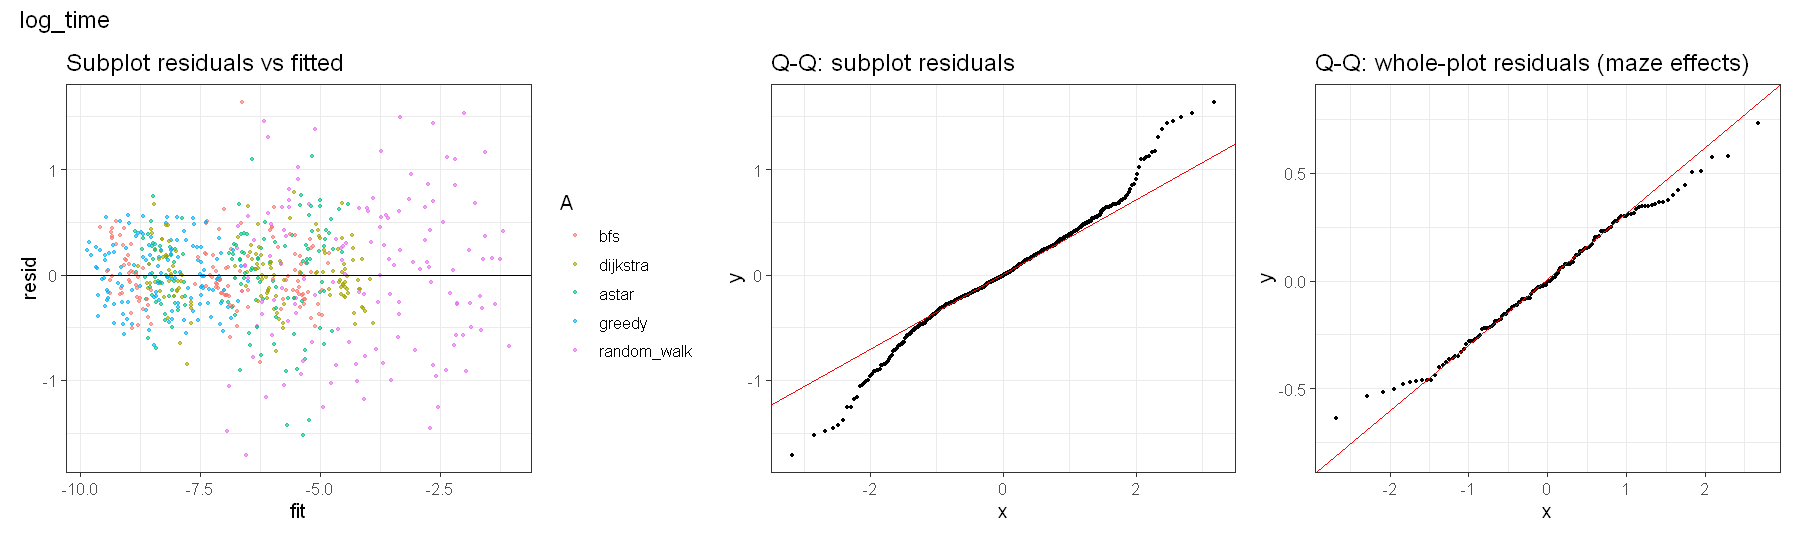

log_nodes : Levene across algorithms p = 3.96e-21 
        bfs    dijkstra       astar      greedy random_walk 
     0.1431      0.1443      0.3692      0.2083      0.2810 


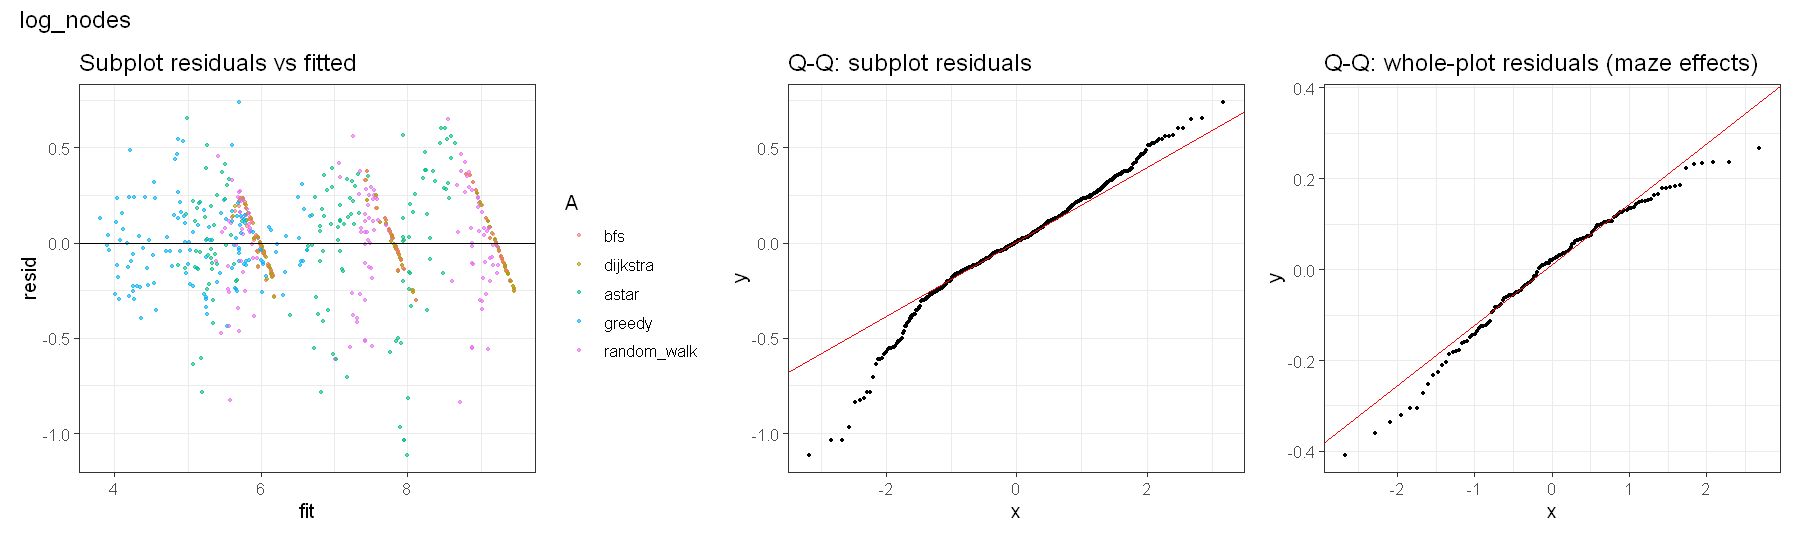

In [70]:
for (y in names(res)) {
  m_sp <- lm(as.formula(paste(y, "~ maze + A + A:S + A:D")), data = df)
  m_wp <- lm(as.formula(paste(y, "~ G + S*D")), data = wp)
  d <- df %>% mutate(fit = fitted(m_sp), resid = resid(m_sp))
  q1 <- ggplot(d, aes(fit, resid, colour = A)) + geom_point(size = .8, alpha = .6) + geom_hline(yintercept = 0) +
    labs(title = "Subplot residuals vs fitted")
  q2 <- ggplot(d, aes(sample = resid)) + stat_qq(size = .7) + stat_qq_line(colour = "red") +
    labs(title = "Q-Q: subplot residuals")
  q3 <- ggplot(data.frame(r = resid(m_wp)), aes(sample = r)) + stat_qq(size = .9) + stat_qq_line(colour = "red") +
    labs(title = "Q-Q: whole-plot residuals (maze effects)")
  print(q1 + q2 + q3 + plot_annotation(title = y))
  lev <- leveneTest(resid ~ A, data = d)
  cat(y, ": Levene across algorithms p =", format(lev$`Pr(>F)`[1], digits = 3), "\n")
  print(round(tapply(d$resid, d$A, sd), 4))
}

### Box-Cox check
Profile log-likelihood of λ for the full subplot model (maze + algorithm terms) on the raw response. λ ≈ 0 supports the log transform.

time_s: lambda_hat = -0.16, 95% CI [-0.18, -0.14]
nodes_explored: lambda_hat = 0.02, 95% CI [-0.02, 0.05]


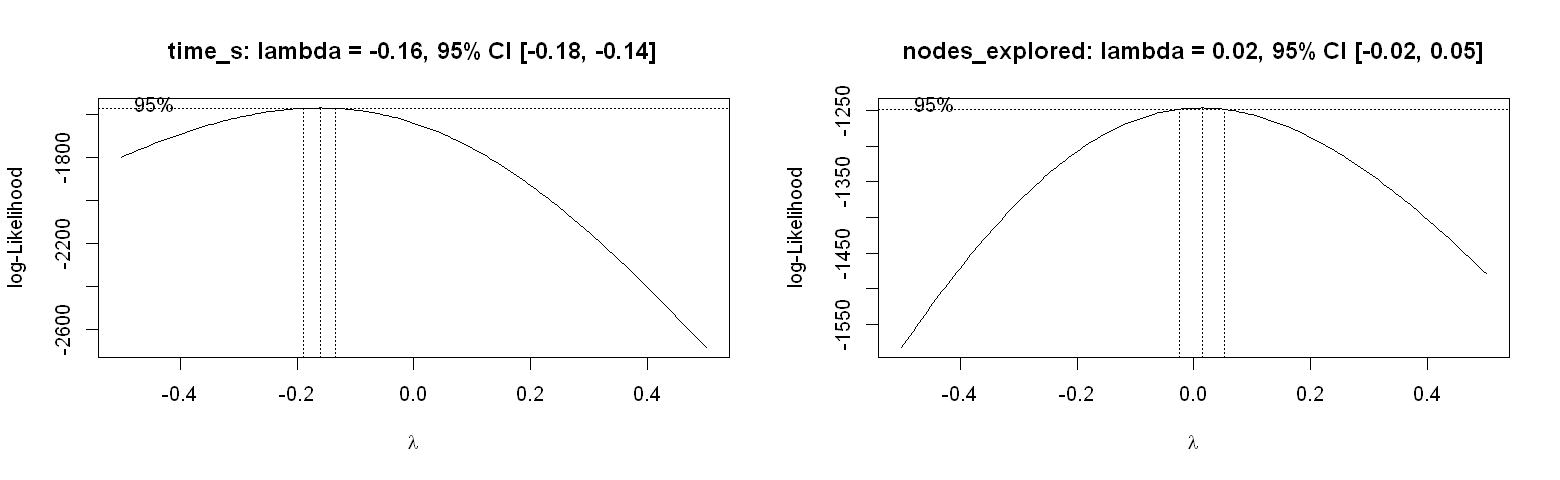

In [71]:
options(repr.plot.width = 13, repr.plot.height = 4)
par(mfrow = c(1, 2))
for (col in c("time_s", "nodes_explored")) {
  bc <- boxcox(as.formula(paste(col, "~ maze + A + A:S + A:D")), data = df,
               lambda = seq(-.5, .5, .005), plotit = TRUE)
  lam <- bc$x[which.max(bc$y)]; ci <- range(bc$x[bc$y > max(bc$y) - qchisq(.95, 1) / 2])
  title(sprintf("%s: lambda = %.2f, 95%% CI [%.2f, %.2f]", col, lam, ci[1], ci[2]))
  cat(sprintf("%s: lambda_hat = %.2f, 95%% CI [%.2f, %.2f]\n", col, lam, ci[1], ci[2]))
}
par(mfrow = c(1, 1)); options(repr.plot.width = 15, repr.plot.height = 4.5)

## 7. Extended subplot model (check the pooling assumption)
The proposal pools A×G and A×S×D into the error. Here they're fitted explicitly to see whether that pooling is reasonable.

In [72]:
for (y in names(res)) {
  t <- split_plot(df, y, sub = "A + A:S + A:D + A:G + A:S:D")$tab
  cat("\n", y, "\n"); print(t[t$Stratum == "Subplot", ], digits = 4)
}


 log_time 
   Stratum          Term  Df   Sum Sq  Mean Sq  F value     Pr(>F)  pct_SS
6  Subplot             A   4 1331.205 332.8012 1428.728 1.371e-270 48.2208
7  Subplot           S:A   8   51.028   6.3785   27.383  3.075e-35  1.8484
8  Subplot           D:A   8   21.754   2.7192   11.674  2.905e-15  0.7880
9  Subplot           G:A   8    6.941   0.8676    3.725  3.034e-04  0.2514
10 Subplot         S:D:A  16    6.799   0.4249    1.824  2.561e-02  0.2463
11 Subplot Subplot error 496  115.536   0.2329       NA         NA  4.1851

 log_nodes 
   Stratum          Term  Df  Sum Sq   Mean Sq  F value     Pr(>F)  pct_SS
6  Subplot             A   4 571.680 142.92005 2228.600 2.497e-315 35.5196
7  Subplot           S:A   8  40.405   5.05061   78.756  2.273e-83  2.5104
8  Subplot           D:A   8   9.521   1.19008   18.557  2.088e-24  0.5915
9  Subplot           G:A   8   6.745   0.84312   13.147  2.860e-17  0.4191
10 Subplot         S:D:A  16   1.638   0.10238    1.596  6.545e-02  0.1018


## 8. Sensitivity: drop the 4 censored random-walk mazes
The 4 mazes are removed entirely (all 5 runs) so every remaining maze still has all algorithms.

In [73]:
bad  <- unique(df$maze_id[df$success == 0])
df_s <- df %>% filter(!maze_id %in% bad) %>% droplevels()
for (y in c("log_time", "log_nodes")) {
  t <- split_plot(df_s, y)$tab
  cat("\n", y, "(mazes =", nlevels(df_s$maze), ")\n"); print(t[, c("Stratum", "Term", "Df", "F value", "Pr(>F)")], digits = 4)
}


 log_time (mazes = 133 )
     Stratum                           Term  Df  F value     Pr(>F)
1 Whole plot                      G (block)   2    7.140  1.169e-03
2 Whole plot                              S   2 1449.574  9.494e-86
3 Whole plot                              D   2   12.628  1.036e-05
4 Whole plot                            S:D   4    1.639  1.688e-01
5 Whole plot Whole-plot error [maze(G,S,D)] 122       NA         NA
6    Subplot                              A   4 1359.405 4.730e-271
7    Subplot                            S:A   8   26.196  5.155e-34
8    Subplot                            D:A   8   10.081  4.244e-13
9    Subplot                  Subplot error 512       NA         NA

 log_nodes (mazes = 133 )
     Stratum                           Term  Df  F value     Pr(>F)
1 Whole plot                      G (block)   2   15.161  1.317e-06
2 Whole plot                              S   2 4723.459 2.725e-116
3 Whole plot                              D   2   25.118  7.316

## 9. Conclusions

**Whole plot (maze level)**
- **Size dominates**: it's the largest single source of variation (≈43% of total SS for log time, ≈60% for log nodes). Both linear and quadratic size trends are significant (the quadratic term appears because the size levels 20/50/100 are unevenly spaced, and cost grows roughly with the number of cells).
- **Loop density** has a small but real effect: more loops mean fewer nodes and less time. The trend is purely linear (quadratic p ≈ 0.7–0.96).
- **S × D** is significant but tiny (≈0.1% SS). For time it drops to p ≈ 0.07 once the 4 censored mazes are removed, so treat it as weak.
- **Generation method (block)** doesn't matter for time (p = 0.21). For nodes it is significant (p < 0.001, Prim's mazes slightly cheaper), but its share of SS is < 0.1%, so blocking bought little.
- Maze-to-maze noise is small: ICC ≈ 0.25 (time), 0.08 (nodes).

**Subplot (algorithm within maze)**
- **Algorithm** is the other dominant factor (≈47% SS time, ≈33% nodes).
- Planned contrasts (ratio of geometric means, all p < 0.001):
  - A* vs Dijkstra: A* explores ~0.42× the nodes and takes ~0.64× the time.
  - Informed vs uninformed: ~0.19× the nodes, ~0.45× the time.
  - Random walk vs rest: ~1.6× the nodes but **~20× the time**, because it revisits cells many times (steps ≫ unique nodes).
- **A × S and A × D are significant**: the informed advantage *grows* with size (nodes ratio 0.30 → 0.14 from 20×20 to 100×100) and with loop density (0.27 → 0.14). So maze structure changes **how much** better an algorithm is.
- It does **not** change **which** algorithm wins: Greedy best-first is fastest and explores the fewest nodes in nearly every maze (87–100% per cell). Its paths are longer than optimal, though (see Section 2), so it trades optimality for speed. Among the optimal methods, A* beats BFS/Dijkstra on nodes everywhere. BFS beats Dijkstra on time (same nodes, less overhead).

**Model checks**
- Box-Cox: λ̂ = −0.15 (time) and 0.05 (nodes). The 95% CIs technically exclude 0 because n = 1350 makes them very narrow, but both are close to 0, so the log stays the practical choice (and keeps the ratio interpretation). λ = −0.15 for time could be tried as a robustness check.
- Residual variance is **not** equal across algorithms (Levene p < 1e-40; random walk and A* are the noisiest). The F tests for A are so large that this won't change conclusions, but the contrast SEs that involve random walk are probably too small. Weighted LS or separate variances per algorithm would be the fix if needed.
- Pooling assumption: A×S×D is negligible for time (p = 0.14) but significant for nodes (p = 0.002, 0.08% SS). A×G is significant for both but small (0.16–0.28% SS). Pooling is fine in practice, but report it.
- Dropping the 4 censored random-walk mazes leaves every conclusion unchanged except S×D for time.